In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [2]:
def describe(df):
    print("Shape: ", df.shape)
    print("\nFirst 5 rows:");  print(df.head())
    print("\nLast 5 rows:");   print(df.tail())
    print("\nInfo:");          df.info()
    print("\nStatistics:");    print(df.describe())
    print("\nMissing values:"); print(df.isnull().sum())

In [3]:
iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names); df["target"] = iris.target
describe(df)

Shape:  (150, 5)

First 5 rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  

Last 5 rows:
     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
145                6.7               3.0                5.2               2.3   
146                6.3               2.5                5.0               1.9   
147                6.5               3.0                5.2               2.0   
148                6.2               3.4                5.4               2.3   
14

In [4]:
X = StandardScaler().fit_transform(iris.data)         # PCA needs scaled data
pca = PCA(n_components=2); X_pca = pca.fit_transform(X)
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance kept:", pca.explained_variance_ratio_.sum())

Explained variance ratio: [0.72962445 0.22850762]
Total variance kept: 0.9581320720000166


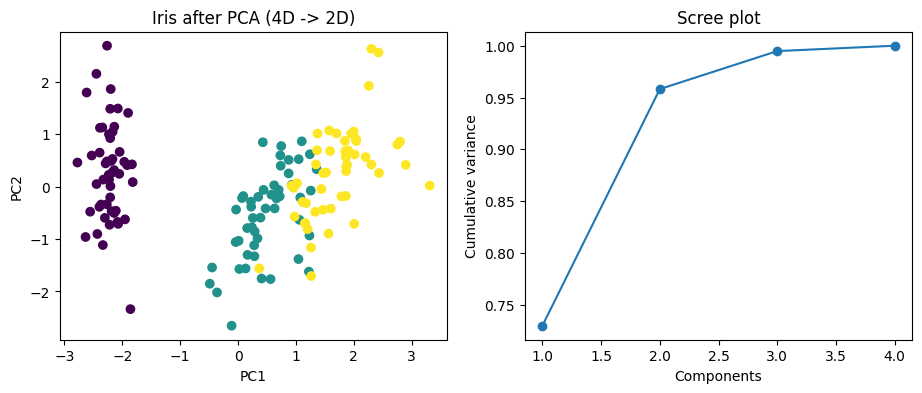

In [5]:
fig,ax = plt.subplots(1,2,figsize=(11,4))
ax[0].scatter(X_pca[:,0],X_pca[:,1],c=iris.target)
ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2"); ax[0].set_title("Iris after PCA (4D -> 2D)")
full = PCA().fit(X)
ax[1].plot(range(1,5),np.cumsum(full.explained_variance_ratio_),marker="o")
ax[1].set_xlabel("Components"); ax[1].set_ylabel("Cumulative variance"); ax[1].set_title("Scree plot")
plt.show()